In [1]:
#partie 1 :Introduction au Dataset
# importer et charger le dataset
import pandas as pd
import seaborn as sns
df = sns.load_dataset("titanic")

In [2]:
# visualiser les premières lignes
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
#identifier les types de données
df.dtypes
#Séparer numériques et catégorielles
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Variables numériques    :", num_cols)
print("Variables catégorielles :", cat_cols)

Variables numériques    : ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
Variables catégorielles : ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [4]:
# verifier les valeurs manquantes
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [5]:
#PARTIE 2 :Nettoyage des Données
#Identifier les colonnes avec des valeurs manquantes
df_clean = df.copy()
df_clean.isnull().sum()
missing_pct = (df_clean.isnull().mean() * 100).round(2)
missing_pct[missing_pct > 0].sort_values(ascending=False)


deck           77.22
age            19.87
embarked        0.22
embark_town     0.22
dtype: float64

In [6]:
#Variables numériques : remplacer par la médiane
df_clean["age"] = df_clean["age"].fillna(df_clean["age"].median())
df_clean["age"].isnull().sum() # verification

np.int64(0)

In [7]:
# Variables catégorielles : remplacer par le mode
df_clean["embarked"] = df_clean["embarked"].fillna(df_clean["embarked"].mode()[0])
df_clean["embark_town"] = df_clean["embark_town"].fillna(df_clean["embark_town"].mode()[0])
print(df_clean[["embarked", "embark_town"]].isnull().sum()) # verification


embarked       0
embark_town    0
dtype: int64


In [8]:
#Supprimer les variables avec plus de 40 % de valeurs manquantes
pct = df_clean.isnull().mean() * 100
cols_a_supprimer = pct[pct > 40].index.tolist()
print(cols_a_supprimer)
df_clean = df_clean.drop(columns=cols_a_supprimer)

['deck']


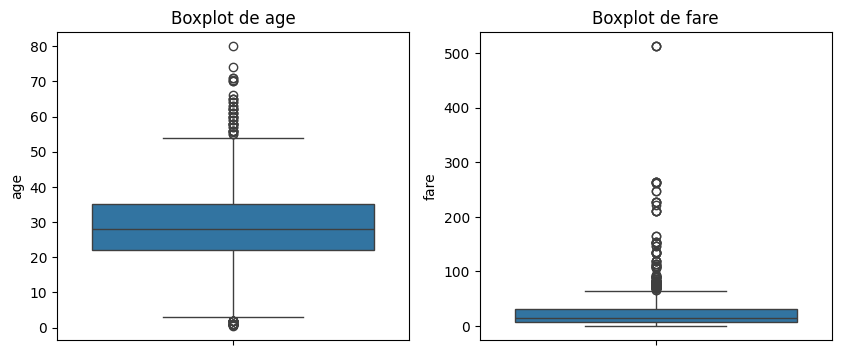

In [9]:
#Détecter avec des boxplots 
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["age", "fare"]):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(f"Boxplot de {col}")
plt.show()

In [10]:

# Remplacer ou supprimer les valeurs aberrantes
# Définir les bornes (règle de l’IQR)
def bornes(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr
# Option A, remplacer par la médiane
df_med = df_clean.copy()
for col in ["age", "fare"]:
    bas, haut = bornes(df_med[col])
    masque = (df_med[col] < bas) | (df_med[col] > haut)
    print(col, ":", masque.sum(), "valeurs remplacées")
    df_med.loc[masque, col] = df_med[col].median()
print(df_med.shape)

age : 66 valeurs remplacées
fare : 116 valeurs remplacées
(891, 14)


In [11]:
# Supprimer les lignes contenant des valeurs aberrantes
df_sup = df_clean.copy()
for col in ["age", "fare"]:
    bas, haut = bornes(df_sup[col])
    df_sup = df_sup[(df_sup[col] >= bas) & (df_sup[col] <= haut)]
print(df_sup.shape)
print("Lignes supprimées :", len(df_clean) - len(df_sup))

(718, 14)
Lignes supprimées : 173


In [12]:
# Partie 3 : Transformation des Données
#Identifier les colonnes catégorielles
cat_cols = df_med.select_dtypes(exclude="number").columns.tolist()
print(cat_cols)

['sex', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive', 'alone']


In [13]:
# Encodage one-hot des variables nominales
df_enc = df_med.copy()
df_enc = pd.get_dummies(df_enc, columns=["sex", "embarked"], drop_first=True, dtype=int)
df_enc.head()

,survived,pclass,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,sex_male,embarked_Q,embarked_S
0,0,3,22.0,1,0,7.2500,Third,man,True,Southampton,no,False,1,0,1
1,1,1,38.0,1,0,14.4542,First,woman,False,Cherbourg,yes,False,0,0,0
2,1,3,26.0,0,0,7.9250,Third,woman,False,Southampton,yes,True,0,0,1
3,1,1,35.0,1,0,53.1000,First,woman,False,Southampton,yes,False,0,0,1
4,0,3,35.0,0,0,8.0500,Third,man,True,Southampton,no,True,1,0,1


In [14]:
# Encodage numérique de la variable ordinale
df_enc["class"] = df_enc["class"].astype(str).map({"First": 1, "Second": 2, "Third": 3})
print(df_enc["class"].value_counts())


class
3    491
1    216
2    184
Name: count, dtype: int64


In [15]:
# [NOUVEAU] Supprimer les colonnes en double (class = pclass, etc.) et la cible en texte (alive)
df_enc = df_enc.drop(columns=["class", "who", "embark_town", "adult_male", "alone", "alive"])
print(df_enc.shape)   # (891, 9)
print(df_enc.columns.tolist())

(891, 9)
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'sex_male', 'embarked_Q', 'embarked_S']


In [16]:
# [NOUVEAU] SÉPARATION DES DONNÉES : train (80 %) / test (20 %)
# Le test est mis de côté : il ne sert qu'à évaluer, jamais à calculer ou rééquilibrer.
from sklearn.model_selection import train_test_split

X = df_enc.drop(columns="survived")   # variables explicatives
y = df_enc["survived"]                # cible

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Proportion de survivants -> train :", round(y_train.mean(), 3), "| test :", round(y_test.mean(), 3))

Train : (712, 8) | Test : (179, 8)
Proportion de survivants -> train : 0.383 | test : 0.385


In [17]:
# [MODIFIÉ] Normalisation (Min-Max) dans [0, 1] : fit sur le TRAIN, transform sur train et test
from sklearn.preprocessing import MinMaxScaler
cols_to_scale = ["age", "fare", "sibsp", "parch"]

mm = MinMaxScaler().fit(X_train[cols_to_scale])
X_train_mm, X_test_mm = X_train.copy(), X_test.copy()
X_train_mm[cols_to_scale] = mm.transform(X_train[cols_to_scale])
X_test_mm[cols_to_scale] = mm.transform(X_test[cols_to_scale])

print(X_train_mm[cols_to_scale].agg(["min", "max"]))

     age  fare  sibsp  parch
min  0.0   0.0    0.0    0.0
max  1.0   1.0    1.0    1.0


In [18]:
# [MODIFIÉ] Standardisation (Z-score) : fit sur le TRAIN, transform sur train et test
from sklearn.preprocessing import StandardScaler

sc = StandardScaler().fit(X_train[cols_to_scale])
X_train_std, X_test_std = X_train.copy(), X_test.copy()
X_train_std[cols_to_scale] = sc.transform(X_train[cols_to_scale])
X_test_std[cols_to_scale] = sc.transform(X_test[cols_to_scale])

print(X_train_std[cols_to_scale].agg(["mean", "std"]).round(3))

        age   fare  sibsp  parch
mean -0.000  0.000 -0.000 -0.000
std   1.001  1.001  1.001  1.001


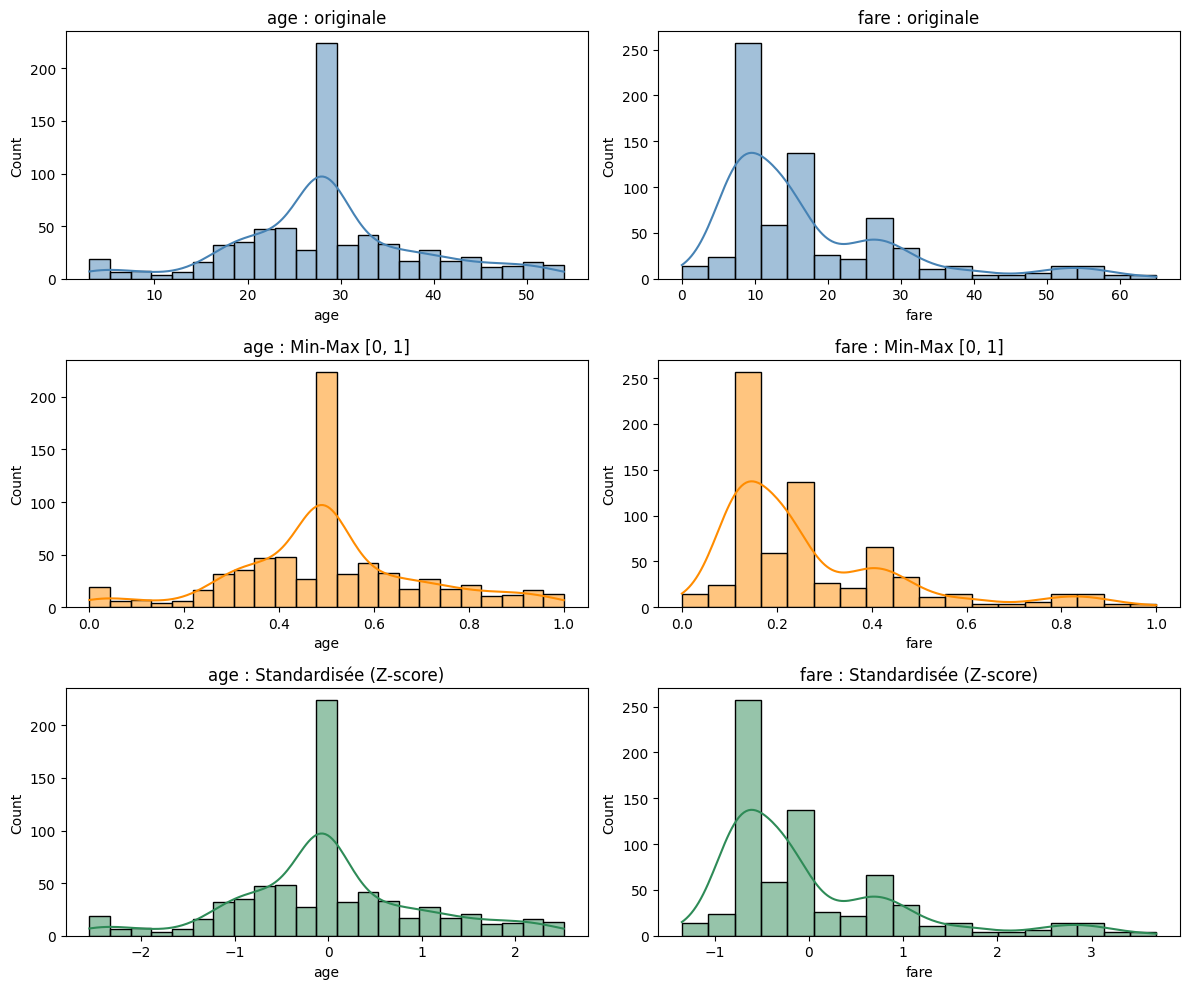

In [19]:
# [MODIFIÉ] Comparer les distributions avec des histogrammes (sur le train)
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for j, col in enumerate(["age", "fare"]):
    sns.histplot(X_train[col], kde=True, ax=axes[0, j], color="steelblue")
    axes[0, j].set_title(f"{col} : originale")
    sns.histplot(X_train_mm[col], kde=True, ax=axes[1, j], color="darkorange")
    axes[1, j].set_title(f"{col} : Min-Max [0, 1]")
    sns.histplot(X_train_std[col], kde=True, ax=axes[2, j], color="seagreen")
    axes[2, j].set_title(f"{col} : Standardisée (Z-score)")
plt.tight_layout()
plt.show()

In [20]:
# [MODIFIÉ] Partie 4 : Identifier le déséquilibre des classes (sur le TRAIN)
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(1))

survived
0    439
1    273
Name: count, dtype: int64
survived
0    61.7
1    38.3
Name: proportion, dtype: float64


In [21]:
# [MODIFIÉ] Sous-échantillonnage (undersampling) : uniquement sur le TRAIN
from sklearn.utils import resample

train = pd.concat([X_train_std, y_train], axis=1)
df_maj = train[train["survived"] == 0]   # classe majoritaire
df_min = train[train["survived"] == 1]   # classe minoritaire

df_maj_reduit = resample(df_maj, replace=False, n_samples=len(df_min), random_state=42)
train_under = pd.concat([df_maj_reduit, df_min]).sample(frac=1, random_state=42)

X_train_under = train_under.drop(columns="survived")
y_train_under = train_under["survived"]
print(y_train_under.value_counts())

survived
1    273
0    273
Name: count, dtype: int64


In [ ]:
# Installation de SMOTE (à exécuter une seule fois, puis redémarrer le noyau si besoin)
!pip install imbalanced-learn

In [23]:
# [MODIFIÉ] Sur-échantillonnage avec SMOTE : uniquement sur le TRAIN
from imblearn.over_sampling import SMOTE

print("Valeurs manquantes :", X_train_std.isnull().sum().sum())   # doit valoir 0
X_train_sm, y_train_sm = SMOTE(random_state=42).fit_resample(X_train_std, y_train)
print(y_train_sm.value_counts())

Valeurs manquantes : 0
survived
1    439
0    439
Name: count, dtype: int64


In [24]:
# [NOUVEAU] Vérification : le test n'a jamais été rééquilibré
print("Test (inchangé) :")
print(y_test.value_counts())

Test (inchangé) :
survived
0    110
1     69
Name: count, dtype: int64
